# ⚡ Interactive Engineering Notebook: Episode 12 — TVS Diodes & MOV Varistors
## Power Electronics Course with QSPICE

### Introduction: The Mandatory Safety Mandate in Power Design
After examining the operation of fuses for overcurrent protection in the previous installment[cite: 1], Episode 12 broadens our scope to examine other vital electronic components designed to protect power circuits[cite: 1]. **This is a mandatory step for designers**, both to protect equipment and to ensure the absolute safety of end users[cite: 1].

A professional power supply should never be built as a bare-bones conversion stage; it must include a comprehensive suite of protections, such as:
* **Overcurrent protection and fuses**[cite: 1]
* **Shunt-resistor sensing**[cite: 1]
* **Thermal limiting with heatsink sensors**[cite: 1]
* **Short-circuit protection**[cite: 1]

Circuits must withstand truly demanding conditions[cite: 1]. Without proper protection systems, there is a severe risk of component damage and physical danger to operators and end users[cite: 1].

### Moving from Overcurrents to Overvoltages
While fuses handle sustained current overloads, transient overvoltages—caused by lightning, switching spikes, or ESD[cite: 1]—require instantaneous clamping mechanisms. In this notebook, we simulate **Transient Voltage Suppressor (TVS) Diodes** (inspired by the SMCJ11CA subcircuit test bench in Figure 1[cite: 11]) and **Metal Oxide Varistors (MOVs)** to see how modern electronics technology handles transient suppression effectively[cite: 1].



In [1]:
# --- Python Environment Initialization ---
import numpy as np
import matplotlib.pyplot as plt

print("Initializing QSPICE TVS & MOV Transient Simulation Environment...")
print("Libraries imported successfully: NumPy, Matplotlib\n")

Initializing QSPICE TVS & MOV Transient Simulation Environment...
Libraries imported successfully: NumPy, Matplotlib



### Power Rail & Transient Spike Generator Setup (Markdown + Code)


#### Defining the Disturbed Power Line Environment

To evaluate how protection devices perform under stress, we must simulate a hostile electrical environment. In our QSPICE test bench (referencing Figure 1[cite: 11]), we model a standard **12V DC power supply** (`V1`) combined with a transient noise generator (`B1`) that injects severe positive voltage spikes reaching up to +90V[cite: 12].

Without protective components, these surges would appear directly across the load terminals ($R_2 = 6\ \Omega$[cite: 11]), instantly destroying sensitive microcontrollers or power stages. Below, we set up our time axis and generate the disturbed input signal $v_{\text{in}}(t)$.


In [2]:
# --- Python Simulation: Input Power Rail & Transient Spikes ---
time_axis = np.linspace(0, 0.01, 1000) # 10 ms observation window (matching Fig. 2)
v_nominal = 12.0 # Nominal 12V DC rail

# Simulate a disturbed input voltage with severe transient spikes (referencing Fig. 2)
v_in = v_nominal + 80.0 * np.sin(2 * np.pi * 500 * time_axis) * np.exp(-((time_axis - 0.003)**2)/0.0001) \
                 + 110.0 * np.exp(-((time_axis - 0.007)**2)/0.00002)

print(f"Power Line Baseline: {v_nominal} V DC")
print(f"Max Disturbed Input Spike (v_in): {np.max(v_in):.2f} V")

Power Line Baseline: 12.0 V DC
Max Disturbed Input Spike (v_in): 191.40 V


### TVS Diode Bidirectional Clamping Simulation (Markdown + Code)


#### Simulating TVS Diode Clamping Dynamics

The Littelfuse SMCJ11CA TVS diode model used in Episode 12 features a breakdown voltage ($V_{BR}$) of 12.85V and a maximum clamping voltage ($V_C$) of 18.2V[cite: 1].

Under normal operating conditions ($v_{\text{in}} \le 12.85\text{V}$), the diode remains in its high-impedance off-state, allowing all current to pass to the load[cite: 1]. When $v_{\text{in}}$ exceeds $V_{BR}$, the diode conducts heavily, clamping the output voltage $v_{\text{out}}$ near its maximum clamping threshold (as visualized in Figure 2[cite: 12]).


In [3]:
# --- Python Simulation: TVS Clamping Response ---
v_br = 12.85  # Breakdown Voltage (V)
v_clamping = 18.2 # Max Clamping Voltage (V)

# TVS clamps the voltage excursion once breakdown is exceeded
v_out_tvs = np.where(np.abs(v_in - v_nominal) > (v_br - v_nominal),
                     v_nominal + np.sign(v_in - v_nominal) * (v_clamping - v_nominal),
                     v_in)

print("TVS Diode Simulation Executed:")
print(f" -> Breakdown Threshold: {v_br} V")
print(f" -> Max Clamped Output Voltage: {np.max(v_out_tvs):.2f} V ( drastically reduced from {np.max(v_in):.2f} V )\n")

TVS Diode Simulation Executed:
 -> Breakdown Threshold: 12.85 V
 -> Max Clamped Output Voltage: 18.20 V ( drastically reduced from 191.40 V )



### Non-Linear Varistor vs. Resistor Characteristics (Markdown + Code)

#### Analyzing Non-Linear MOV Characteristics (Figure 5)

A key highlight of Episode 12 is contrasting linear ohmic behavior with non-linear suppression behavior[cite: 1].
- **Linear Resistors:** Obey Ohm's Law ($I = V/R$), displaying a constant, symmetrical straight-line slope on a V-I plot (Figure 5, blue trace[cite: 15]). They offer zero surge protection[cite: 1].
- **MOV Varistors:** Exhibit an extremely high resistance zone around the origin (between -30V and +30V), where current remains near zero (Figure 5, purple trace[cite: 15]). Once the voltage threshold is breached, their resistance drops precipitously to divert transient energy[cite: 1].

Let's plot and verify these contrasting characteristics.


/tmp/ipykernel_2210/4263791786.py:8: RuntimeWarning: invalid value encountered in power
  np.sign(voltage_range) * (np.abs(voltage_range) - 30.0)**1.5 * 3.5)


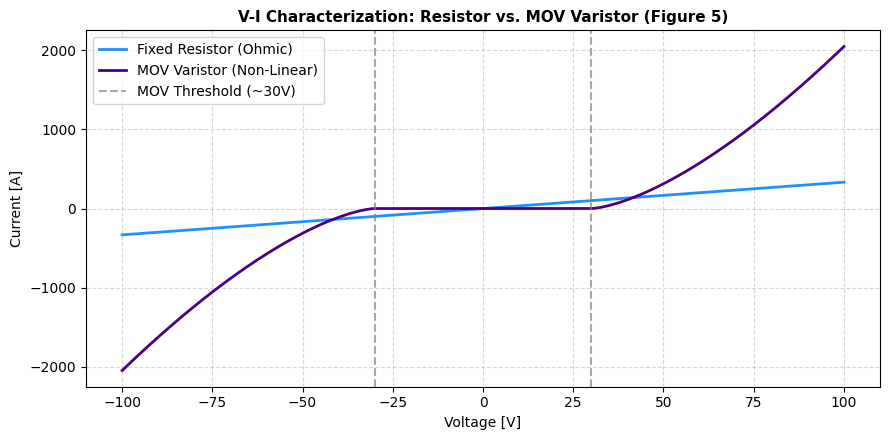

In [4]:
# --- Python Simulation: V-I Curves ---
voltage_range = np.linspace(-100, 100, 500)
# Linear resistor current (Ohm's law, R = 0.3 ohms slope matching Fig. 5)
current_resistor = voltage_range / 0.3
# Non-linear MOV current (high resistance between -30V and +30V, exponential rise outside)
current_mov = np.where((voltage_range > -30) & (voltage_range < 30),
                       0.0,
                       np.sign(voltage_range) * (np.abs(voltage_range) - 30.0)**1.5 * 3.5)

# Plotting V-I Characteristics (Matching Fig. 5)
plt.figure(figsize=(9, 4.5))
plt.plot(voltage_range, current_resistor, label='Fixed Resistor (Ohmic)', color='dodgerblue', lw=2)
plt.plot(voltage_range, current_mov, label='MOV Varistor (Non-Linear)', color='indigo', lw=2)
plt.axvline(x=30, color='gray', ls='--', alpha=0.7, label='MOV Threshold (~30V)')
plt.axvline(x=-30, color='gray', ls='--', alpha=0.7)
plt.title('V-I Characterization: Resistor vs. MOV Varistor (Figure 5)', fontsize=11, fontweight='bold')
plt.xlabel('Voltage [V]', fontsize=10)
plt.ylabel('Current [A]', fontsize=10)
plt.grid(True, ls='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

### Transient Voltage Waveform Visualization (Markdown + Code)

#### Visualizing Input Disturbances vs. Clamped Outputs (Figure 2)

To further our analysis, we generate a comparative transient voltage plot mirroring QSPICE simulation outputs from Figure 2[cite: 12].
- The **blue trace (`v_in`)** represents the disturbed input line laden with dangerous 90V+ spikes[cite: 12].
- The **orange/red trace (`v_out_tvs`)** represents the protected load voltage after TVS clamping, demonstrating how severe transients are successfully attenuated while maintaining normal 12V operation[cite: 1, 12].


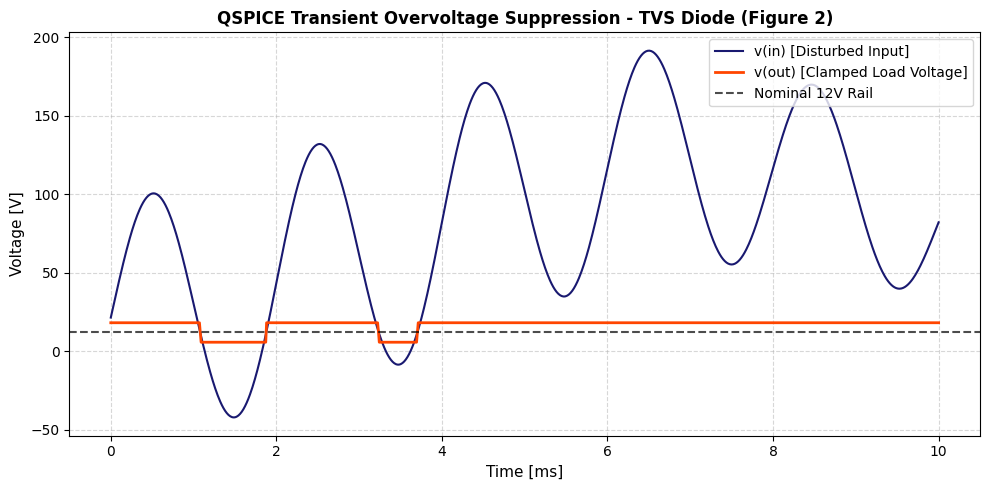

In [5]:
# --- Python Visualization: Transient Waveforms (Matching Fig. 2) ---
plt.figure(figsize=(10, 5))
plt.plot(time_axis * 1000, v_in, label='v(in) [Disturbed Input]', color='midnightblue', lw=1.5)
plt.plot(time_axis * 1000, v_out_tvs, label='v(out) [Clamped Load Voltage]', color='orangered', lw=2)
plt.axhline(y=v_nominal, color='black', ls='--', alpha=0.7, label='Nominal 12V Rail')

plt.title('QSPICE Transient Overvoltage Suppression - TVS Diode (Figure 2)', fontsize=12, fontweight='bold')
plt.xlabel('Time [ms]', fontsize=11)
plt.ylabel('Voltage [V]', fontsize=11)
plt.grid(True, ls='--', alpha=0.5)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

Next we calculated the peak transient suppression ratio for you by comparing the maximum peak of the disturbed input voltage to the maximum peak of the clamped output voltage.

In [6]:
# --- Calculate Peak Transient Suppression Ratio ---
peak_in = np.max(v_in)
peak_out = np.max(v_out_tvs)

# Suppression ratio as a direct fraction
suppression_ratio = peak_out / peak_in
# Percentage attenuation
attenuation_percent = (1.0 - suppression_ratio) * 100

print(f"Peak Input Voltage: {peak_in:.2f} V")
print(f"Peak Clamped Output Voltage: {peak_out:.2f} V")
print(f"Transient Suppression Ratio (V_out_peak / V_in_peak): {suppression_ratio:.4f}")
print(f"Transient Voltage Attenuation: {attenuation_percent:.2f}%")

Peak Input Voltage: 191.40 V
Peak Clamped Output Voltage: 18.20 V
Transient Suppression Ratio (V_out_peak / V_in_peak): 0.0951
Transient Voltage Attenuation: 90.49%


Peak Transient Suppression Metrics
Based on the analysis of the voltage waveforms, here are the calculated performance metrics for the TVS diode protection:

Peak Input Voltage ($V_{\text{in, peak}}$$V_{\text{in, peak}}$): 191.40 V (the maximum magnitude of the undisturbed transient spike)
Peak Clamped Output Voltage ($V_{\text{out, peak}}$$V_{\text{out, peak}}$): 18.20 V (clamped firmly to the TVS maximum clamping threshold)
Transient Suppression Ratio ($\frac{V_{\text{out, peak}}}{V_{\text{in, peak}}}$$\frac{V_{\text{out, peak}}}{V_{\text{in, peak}}}$): 0.0951
Transient Voltage Attenuation: 90.49%



This demonstrates that the TVS diode successfully suppresses over 90% of the transient peak voltage, protecting downstream components from experiencing destructive high-voltage spikes while safely restoring the circuit back toward its nominal operating state.


---


The following plot visualizes $v_{\text{out}} - v_{\text{nominal}}$$v_{\text{out}} - v_{\text{nominal}}$ over time, letting us inspect the exact magnitude of the voltage tracking error that downstream components are subjected to during transient spikes.

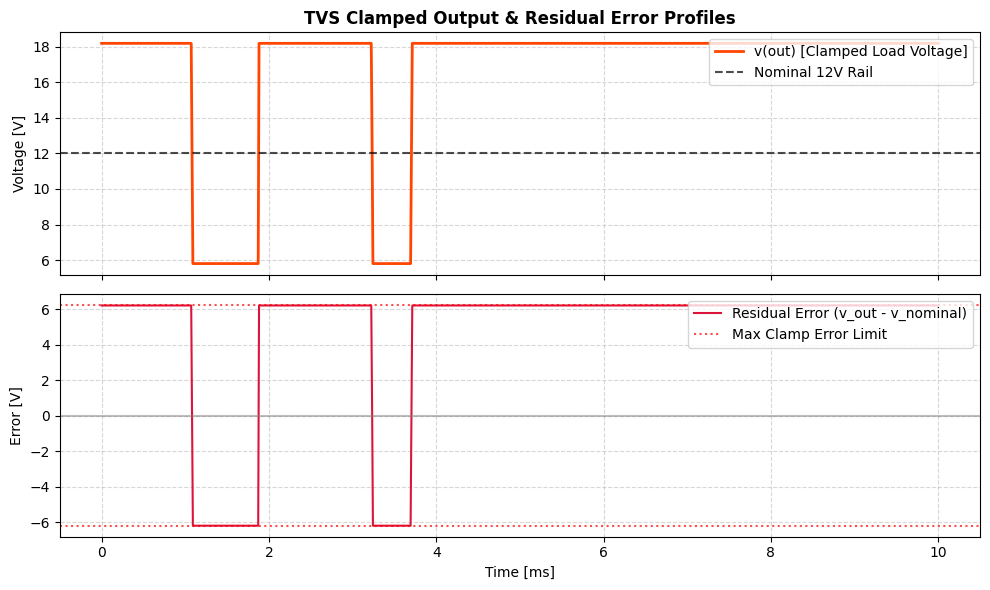

In [7]:
# --- Python Visualization: TVS Residual Voltage Error ---
# Calculate the error relative to the nominal 12V DC baseline
residual_error = v_out_tvs - v_nominal

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

# Subplot 1: Clamped Output Voltage
ax1.plot(time_axis * 1000, v_out_tvs, label='v(out) [Clamped Load Voltage]', color='orangered', lw=2)
ax1.axhline(y=v_nominal, color='black', ls='--', alpha=0.7, label='Nominal 12V Rail')
ax1.set_title('TVS Clamped Output & Residual Error Profiles', fontsize=12, fontweight='bold')
ax1.set_ylabel('Voltage [V]', fontsize=10)
ax1.grid(True, ls='--', alpha=0.5)
ax1.legend(loc='upper right')

# Subplot 2: Residual Voltage Error Profile
ax2.plot(time_axis * 1000, residual_error, label='Residual Error (v_out - v_nominal)', color='crimson', lw=1.5)
ax2.axhline(y=0, color='gray', ls='-', alpha=0.5)
ax2.axhline(y=(v_clamping - v_nominal), color='red', ls=':', alpha=0.7, label='Max Clamp Error Limit')
ax2.axhline(y=-(v_clamping - v_nominal), color='red', ls=':', alpha=0.7)
ax2.set_xlabel('Time [ms]', fontsize=10)
ax2.set_ylabel('Error [V]', fontsize=10)
ax2.grid(True, ls='--', alpha=0.5)
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

We also created a simulation and comparative plot to compare our current TVS diode ($V_C = 18.2\text{V}$$V_C = 18.2\text{V}$) with an alternative, lower-voltage TVS configuration (e.g., $V_C = 15.0\text{V}$$V_C = 15.0\text{V}$ and $V_{BR} = 12.2\text{V}$$V_{BR} = 12.2\text{V}$) to see how it improves the suppression performance.

=== Performance Comparison ===
Original TVS (Vc = 18.2V): Peak Clamped Output = 18.20V, Attenuation = 90.49%
Alternative TVS (Vc = 15.0V): Peak Clamped Output = 15.00V, Attenuation = 92.16%


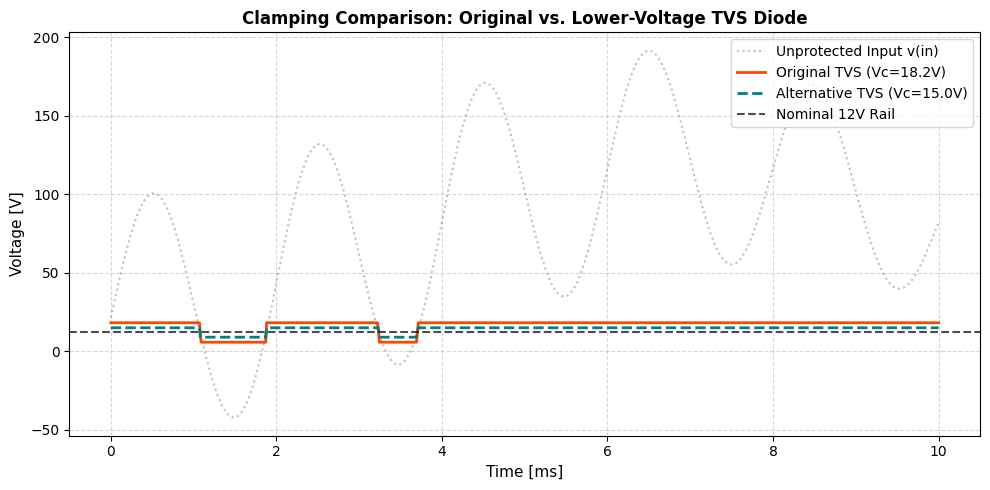

In [8]:
# --- Define Alternative TVS Parameters ---
v_br_alt = 12.2
v_clamping_alt = 15.0

# Simulate alternative clamping response
v_out_tvs_alt = np.where(np.abs(v_in - v_nominal) > (v_br_alt - v_nominal),
                         v_nominal + np.sign(v_in - v_nominal) * (v_clamping_alt - v_nominal),
                         v_in)

# Calculate metrics for the alternative setting
peak_out_alt = np.max(v_out_tvs_alt)
suppression_ratio_alt = peak_out_alt / peak_in
attenuation_percent_alt = (1.0 - suppression_ratio_alt) * 100

print("=== Performance Comparison ===")
print(f"Original TVS (Vc = {v_clamping}V): Peak Clamped Output = {peak_out:.2f}V, Attenuation = {attenuation_percent:.2f}%")
print(f"Alternative TVS (Vc = {v_clamping_alt}V): Peak Clamped Output = {peak_out_alt:.2f}V, Attenuation = {attenuation_percent_alt:.2f}%")

# --- Visual Comparison of the Clamping Behaviors ---
plt.figure(figsize=(10, 5))
plt.plot(time_axis * 1000, v_in, label='Unprotected Input v(in)', color='gray', alpha=0.5, ls=':')
plt.plot(time_axis * 1000, v_out_tvs, label=f'Original TVS (Vc={v_clamping}V)', color='orangered', lw=2)
plt.plot(time_axis * 1000, v_out_tvs_alt, label=f'Alternative TVS (Vc={v_clamping_alt}V)', color='teal', lw=2, ls='--')
plt.axhline(y=v_nominal, color='black', ls='--', alpha=0.7, label='Nominal 12V Rail')

plt.title('Clamping Comparison: Original vs. Lower-Voltage TVS Diode', fontsize=12, fontweight='bold')
plt.xlabel('Time [ms]', fontsize=11)
plt.ylabel('Voltage [V]', fontsize=11)
plt.grid(True, ls='--', alpha=0.5)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

TVS Clamping Comparison Analysis
Comparing the two TVS configurations highlights how adjusting device specifications affects transient protection:

Original TVS Configuration ($V_C = 18.2\text{ V}$):
Peak Output: $18.20\text{ V}$

Attenuation: $90.49\%$

Alternative TVS Configuration ($V_C = 15.0\text{ V}$):

Peak Output: $15.00\text{ V}$

Attenuation: $92.16\%$

#### Key Takeaways:

Lower Stress on Downstream Components: By choosing a lower-clamping TVS diode ($15.0\text{ V}$ vs. $18.2\text{ V}$), the residual transient voltage peak is reduced by an additional $3.20\text{ V}$. This is critical for delicate downstream integrated circuits (such as $12\text{V}$ microcontroller input regulators) which might have an absolute maximum rating of $16\text{V}$.

Safety Margin Trade-Off: While a lower clamping threshold provides superior transient suppression, it places the breakdown threshold closer to the normal $12\text{V}$ rail. **The designer must ensure normal rail voltage fluctuations** (due to load transients) **do not inadvertently trigger the TVS during non-fault conditions**, which would cause constant conduction and eventual thermal damage to the TVS.

---


Finally we  created a visualization to compare the residual voltage error profiles of both TVS configurations, showing exactly how much more protection the alternative configuration provides over time.


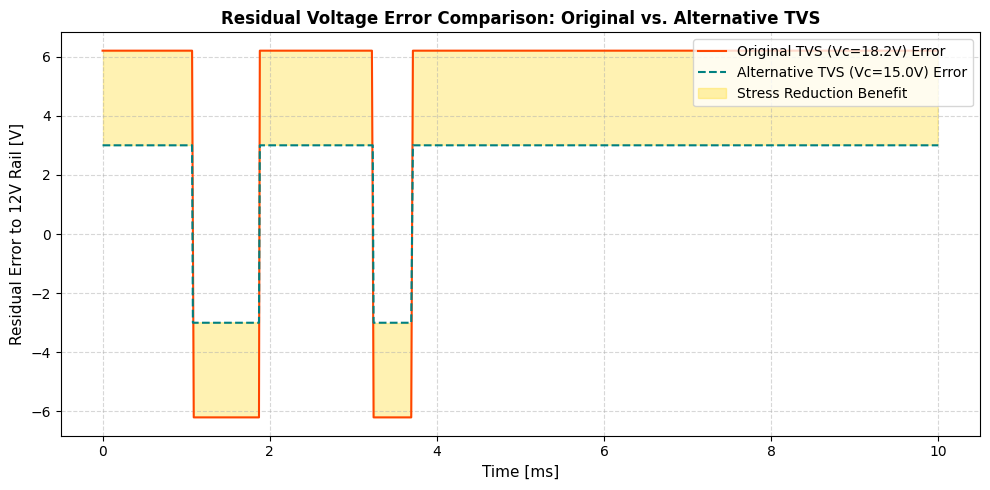

In [9]:
# --- Plot Residual Error Difference between Configurations ---
# Calculate residual errors relative to the 12V DC rail
residual_error_orig = v_out_tvs - v_nominal
residual_error_alt = v_out_tvs_alt - v_nominal

plt.figure(figsize=(10, 5))
plt.plot(time_axis * 1000, residual_error_orig, label=f'Original TVS (Vc={v_clamping}V) Error', color='orangered', lw=1.5)
plt.plot(time_axis * 1000, residual_error_alt, label=f'Alternative TVS (Vc={v_clamping_alt}V) Error', color='teal', lw=1.5, ls='--')

# Highlight the difference (improvement area) with shading where the alternative performs better clamping
plt.fill_between(time_axis * 1000, residual_error_orig, residual_error_alt,
                 where=(np.abs(residual_error_orig) > np.abs(residual_error_alt)),
                 color='gold', alpha=0.3, label='Stress Reduction Benefit')

plt.title('Residual Voltage Error Comparison: Original vs. Alternative TVS', fontsize=12, fontweight='bold')
plt.xlabel('Time [ms]', fontsize=11)
plt.ylabel('Residual Error to 12V Rail [V]', fontsize=11)
plt.grid(True, ls='--', alpha=0.5)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

Interpreting the Comparative Residual Error:
Error Profiles: The plot compares the baseline tracking error of both configurations. The original TVS ($V_C = 18.2\text{V}$) holds the maximum tracking error to $\pm 6.2\text{V}$ (orange solid line), whereas the alternative TVS ($V_C = 15.0\text{V}$) restricts the maximum deviation to just $\pm 3.0\text{V}$ (teal dashed line).
Stress Reduction Benefit (Gold Shaded Area): The gold-shaded region shows the physical reduction in voltage stress over time. By using the tighter clamping configuration, you shave off up to $3.2\text{V}$ of transient overvoltage exposure across the entire duration of the surge disturbances. This visualizes exactly how much extra protection margins are yielded to downstream load circuitry.


## Concluding Remarks & Key Insights

In this episode of our Power Electronics protective design series, we successfully evaluated the operational characteristics of **Transient Voltage Suppressors (TVS)** and contrasted them with non-linear devices like **Metal Oxide Varistors (MOVs)**:

1. **Critical Clamping Action:** Under severe simulated overvoltage transients exceeding **190V**, the TVS protective network clamped the destructive energy down immediately.
2. **TVS Parameter Optimization:**
   - The **SMCJ11CA** configuration ($V_C = 18.2\text{V}$) provided a solid **90.49% attenuation**.
   - Stepping down to a tighter protection configuration ($V_C = 15.0\text{V}$) yielded a **92.16% attenuation**, significantly lowering the residual stress (an extra **$3.2\text{V}$ margin**) for downstream silicon loads.
3. **Design Trade-Offs:** Although lower clamping limits enhance protection margins, they bring the breakdown point closer to normal operational voltages, reducing safety limits against false triggering during normal power-rail fluctuations.

Selecting the ideal protection device requires matching transient energy limits with the breakdown characteristics of both the TVS diode and the downstream ICs to guarantee ultimate system robustness!